# Eksplorasi Data dan Preprocessing Film

Notebook ini digunakan untuk memahami kondisi awal dataset film, membersihkan data yang tidak sesuai, membentuk fitur untuk sistem rekomendasi, lalu menyimpan hasilnya agar dapat digunakan oleh algoritma Fuzzy C-Means (FCM) dan K-Nearest Neighbors (KNN).

Alur pengerjaan:
1. Memuat dataset mentah dari folder lokal proyek.
2. Melakukan Exploratory Data Analysis (EDA) untuk melihat struktur, distribusi, dan masalah pada data.
3. Membersihkan data dan memilih film yang memenuhi kriteria.
4. Membentuk fitur numerik dan genre.
5. Melakukan normalisasi dan reduksi dimensi dengan PCA.
6. Menyimpan dataset hasil preprocessing serta parameter transformasinya.
7. Memvalidasi hasil dan menguji fungsi untuk memproses data film baru.



EDA

## 1. Persiapan dan Memuat Dataset

Bagian ini mengimpor pustaka yang diperlukan, menentukan lokasi dataset pada folder proyek, dan membaca dataset `movies_metadata`.csv dari folder `data/raw/TheMovieDataset/`. Dataset mentah menjadi sumber data untuk seluruh proses EDA dan preprocessing.

In [1]:
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

# Menentukan lokasi utama proyek
PROJECT_ROOT = Path.cwd()

# Jika notebook dijalankan dari folder notebooks,
# naik satu tingkat ke folder utama proyek
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Menentukan lokasi dataset mentah dan hasil preprocessing
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "TheMovieDataset"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Membuat folder hasil jika belum tersedia
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Lokasi proyek:", PROJECT_ROOT)
print("Lokasi dataset:", RAW_DIR)
print("Lokasi hasil:", PROCESSED_DIR)

Lokasi proyek: c:\rekomendasi-film-fcm
Lokasi dataset: c:\rekomendasi-film-fcm\data\raw\TheMovieDataset
Lokasi hasil: c:\rekomendasi-film-fcm\data\processed


In [3]:
import os

# Melihat file yang tersedia di folder dataset
os.listdir(RAW_DIR)

['credits.csv',
 'keywords.csv',
 'links.csv',
 'links_small.csv',
 'movies_metadata.csv',
 'ratings.csv',
 'ratings_small.csv']

In [4]:
file_path = RAW_DIR / "movies_metadata.csv"

df_movies = pd.read_csv(file_path)

C:\Users\THINKPAD\AppData\Local\Temp\ipykernel_12100\1631671011.py:3: DtypeWarning: Columns (10: popularity) have mixed types. Specify dtype option on import or set low_memory=False.
  df_movies = pd.read_csv(file_path)


### 1.1 Memahami Struktur Dataset

Pemeriksaan awal dilakukan untuk mengetahui jumlah baris dan kolom, nama atribut, serta contoh isi data. Informasi ini membantu menentukan kolom yang relevan untuk sistem rekomendasi.

In [5]:
df_movies.shape

(45466, 24)

In [6]:
df_movies.columns.tolist()

['adult',
 'belongs_to_collection',
 'budget',
 'genres',
 'homepage',
 'id',
 'imdb_id',
 'original_language',
 'original_title',
 'overview',
 'popularity',
 'poster_path',
 'production_companies',
 'production_countries',
 'release_date',
 'revenue',
 'runtime',
 'spoken_languages',
 'status',
 'tagline',
 'title',
 'video',
 'vote_average',
 'vote_count']

In [7]:
df_movies.head()

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


In [8]:
df_movies[['title', 'genres', 'popularity', 'vote_average', 'vote_count', 'runtime', 'release_date']].head(10)

,title,genres,popularity,vote_average,vote_count,runtime,release_date
0,Toy Story,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",21.946943,7.7,5415.0,81.0,1995-10-30
1,Jumanji,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",17.015539,6.9,2413.0,104.0,1995-12-15
2,Grumpier Old Men,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",11.7129,6.5,92.0,101.0,1995-12-22
3,Waiting to Exhale,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",3.859495,6.1,34.0,127.0,1995-12-22
4,Father of the Bride Part II,"[{'id': 35, 'name': 'Comedy'}]",8.387519,5.7,173.0,106.0,1995-02-10
5,Heat,"[{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...",17.924927,7.7,1886.0,170.0,1995-12-15
6,Sabrina,"[{'id': 35, 'name': 'Comedy'}, {'id': 10749, '...",6.677277,6.2,141.0,127.0,1995-12-15
7,Tom and Huck,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",2.561161,5.4,45.0,97.0,1995-12-22
8,Sudden Death,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",5.23158,5.5,174.0,106.0,1995-12-22
9,GoldenEye,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",14.686036,6.6,1194.0,130.0,1995-11-16


### 1.2 Memeriksa Kualitas Data

Kolom utama yang diamati adalah judul, genre, popularitas, rating, jumlah vote, durasi, dan tanggal rilis. Pemeriksaan missing value dan tipe data dilakukan untuk menemukan nilai kosong atau format yang perlu diperbaiki.

In [9]:
kolom_fitur = ['title', 'genres', 'popularity', 'vote_average', 'vote_count', 'runtime', 'release_date']

df_movies[kolom_fitur].isnull().sum()

title             6
genres            0
popularity        5
vote_average      6
vote_count        6
runtime         263
release_date     87
dtype: int64

In [10]:
df_movies[kolom_fitur].dtypes

title               str
genres              str
popularity       object
vote_average    float64
vote_count      float64
runtime         float64
release_date        str
dtype: object

### 1.3 Pemeriksaan Nilai Tidak Valid dan Anomali

Pada bagian ini dilakukan pemeriksaan terhadap nilai popularitas dan ID yang tidak dapat dikonversi menjadi angka. Tujuannya adalah mengidentifikasi baris yang berpotensi rusak sebelum proses pembersihan.

In [11]:
popularity_numeric = pd.to_numeric(df_movies['popularity'], errors='coerce')

data_popularity_aneh = df_movies[
    popularity_numeric.isna() & df_movies['popularity'].notna()
]

data_popularity_aneh[['title', 'popularity']].head(20)

,title,popularity
35587,NaN,Beware Of Frost Bites


In [12]:
df_movies.loc[35587]

adult                     Avalanche Sharks tells the story of a bikini ...
belongs_to_collection                                             2.185485
budget                                    /zaSf5OG7V8X8gqFvly88zDdRm46.jpg
genres                   [{'name': 'Odyssey Media', 'id': 17161}, {'nam...
homepage                          [{'iso_3166_1': 'CA', 'name': 'Canada'}]
id                                                              2014-01-01
imdb_id                                                                  0
original_language                                                     82.0
original_title                    [{'iso_639_1': 'en', 'name': 'English'}]
overview                                                          Released
popularity                                           Beware Of Frost Bites
poster_path                                               Avalanche Sharks
production_companies                                                 False
production_countries     

In [13]:
popularity_numeric = pd.to_numeric(df_movies['popularity'], errors='coerce')

jumlah_popularity_invalid = (
    popularity_numeric.isna() & df_movies['popularity'].notna()
).sum()

print("Jumlah popularity tidak valid:", jumlah_popularity_invalid)

Jumlah popularity tidak valid: 1


In [14]:
id_numeric = pd.to_numeric(df_movies['id'], errors='coerce')

jumlah_id_invalid = (
    id_numeric.isna() & df_movies['id'].notna()
).sum()

print("Jumlah ID film tidak valid:", jumlah_id_invalid)

Jumlah ID film tidak valid: 3


In [15]:
id_numeric = pd.to_numeric(df_movies['id'], errors='coerce')

data_id_aneh = df_movies[
    id_numeric.isna() & df_movies['id'].notna()
]

data_id_aneh[['id', 'title', 'original_title', 'release_date', 'genres']]

,id,title,original_title,release_date,genres
19730,1997-08-20,NaN,"[{'iso_639_1': 'en', 'name': 'English'}]",1,"[{'name': 'Carousel Productions', 'id': 11176}..."
29503,2012-09-29,NaN,"[{'iso_639_1': 'ja', 'name': '日本語'}]",12,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go..."
35587,2014-01-01,NaN,"[{'iso_639_1': 'en', 'name': 'English'}]",22,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam..."


In [16]:
id_numeric = pd.to_numeric(df_movies['id'], errors='coerce')

jumlah_id_duplikat = id_numeric[id_numeric.notna()].duplicated().sum()

print("Jumlah ID film duplikat:", jumlah_id_duplikat)

Jumlah ID film duplikat: 30


In [17]:
film_id_duplikat = df_movies[
    id_numeric.notna() & id_numeric.duplicated(keep=False)
].sort_values('id')

film_id_duplikat[['id', 'title', 'original_title', 'release_date']].head(20)

,id,title,original_title,release_date
676,105045,The Promise,Das Versprechen,1995-02-16
1465,105045,The Promise,Das Versprechen,1995-02-16
4114,10991,Pokémon: Spell of the Unknown,Pokémon 3: The Movie,2000-07-08
44821,10991,Pokémon: Spell of the Unknown,Pokémon 3: The Movie,2000-07-08
5710,109962,Rich and Famous,Rich and Famous,1981-09-23
20899,109962,Rich and Famous,Rich and Famous,1981-09-23
4356,110428,Camille Claudel 1915,Camille Claudel 1915,2013-03-13
23534,110428,Camille Claudel 1915,Camille Claudel 1915,2013-03-13
14012,11115,Deal,Deal,2008-01-29
24844,11115,Deal,Deal,2008-01-29


In [18]:
id_numeric = pd.to_numeric(df_movies['id'], errors='coerce')

mask_id_valid = id_numeric.notna()

jumlah_id_berulang = id_numeric[mask_id_valid].value_counts()
jumlah_id_berulang = jumlah_id_berulang[jumlah_id_berulang > 1]

print("Jumlah ID yang berulang:", len(jumlah_id_berulang))
print("Jumlah baris duplikat yang berlebih:", (jumlah_id_berulang - 1).sum())

Jumlah ID yang berulang: 29
Jumlah baris duplikat yang berlebih: 30


### 1.4 Pemeriksaan Duplikasi dan Genre

Bagian ini memeriksa baris duplikat, genre kosong, serta variasi penulisan atau isi genre. Informasi tersebut digunakan untuk menentukan aturan pembersihan data.

In [19]:
jumlah_duplikat_baris = df_movies.duplicated().sum()

print("Jumlah baris yang identik sepenuhnya:", jumlah_duplikat_baris)

Jumlah baris yang identik sepenuhnya: 13


In [20]:
jumlah_genre_kosong = (
    df_movies['genres'].isna() |
    (df_movies['genres'].astype(str).str.strip() == '[]') |
    (df_movies['genres'].astype(str).str.strip() == '')
).sum()

print("Jumlah genre kosong:", jumlah_genre_kosong)

Jumlah genre kosong: 2442


In [21]:
import ast

genre_counts = {}

for genre_data in df_movies['genres']:
    try:
        genres = ast.literal_eval(genre_data) if isinstance(genre_data, str) else []

        for genre in genres:
            nama_genre = genre.get('name')
            if nama_genre:
                genre_counts[nama_genre] = genre_counts.get(nama_genre, 0) + 1

    except (ValueError, SyntaxError):
        continue

df_genre_counts = pd.DataFrame(
    genre_counts.items(),
    columns=['Genre', 'Jumlah Film']
).sort_values('Jumlah Film', ascending=False)

df_genre_counts

,Genre,Jumlah Film
6,Drama,20265
1,Comedy,13182
9,Thriller,7624
5,Romance,6735
7,Action,6596
10,Horror,4673
8,Crime,4307
17,Documentary,3932
3,Adventure,3496
12,Science Fiction,3049


### 1.5 Melihat Distribusi Fitur

Distribusi fitur numerik seperti popularitas, jumlah vote, durasi, tahun rilis, dan rating diperiksa menggunakan statistik serta visualisasi. Pemeriksaan ini membantu memahami rentang data dan menemukan nilai yang tidak wajar.

In [22]:
kolom_numerik = [
    'popularity',
    'vote_average',
    'vote_count',
    'runtime'
]

df_movies[kolom_numerik].describe()

,vote_average,vote_count,runtime
count,45460.000000,45460.000000,45203.000000
mean,5.618207,109.897338,94.128199
std,1.924216,491.310374,38.407810
min,0.000000,0.000000,0.000000
25%,5.000000,3.000000,85.000000
50%,6.000000,10.000000,95.000000
75%,6.800000,34.000000,107.000000
max,10.000000,14075.000000,1256.000000


In [23]:
runtime_aneh = df_movies[
    (df_movies['runtime'] <= 0) |
    (df_movies['runtime'] > 300)
]

runtime_aneh[['title', 'runtime', 'release_date', 'vote_count']].sort_values(
    'runtime', ascending=False
)

,title,runtime,release_date,vote_count
24178,Centennial,1256.0,1978-10-01,8.0
19965,Jazz,1140.0,2001-01-09,3.0
40938,Baseball,1140.0,1994-09-18,4.0
13767,Berlin Alexanderplatz,931.0,1980-08-28,5.0
13953,Heimat: A Chronicle of Germany,925.0,1984-09-16,1.0
...,...,...,...,...
44734,El Violetero,0.0,1960-11-24,0.0
44707,McDougal's Rest Farm,0.0,1947-01-30,0.0
44706,Stupidstitious Cat,0.0,1947-04-24,1.0
44676,Photographer,0.0,2015-01-08,3.0


In [24]:
jumlah_runtime_nol = (df_movies['runtime'] <= 0).sum()
jumlah_runtime_diatas300 = (df_movies['runtime'] > 300).sum()

print("Runtime 0 atau negatif:", jumlah_runtime_nol)
print("Runtime di atas 300 menit:", jumlah_runtime_diatas300)

Runtime 0 atau negatif: 1558
Runtime di atas 300 menit: 108


In [25]:
popularity_numeric = pd.to_numeric(
    df_movies['popularity'], errors='coerce'
)

popularity_numeric.describe()

count    45460.000000
mean         2.921478
std          6.005414
min          0.000000
25%          0.385948
50%          1.127685
75%          3.678902
max        547.488298
Name: popularity, dtype: float64

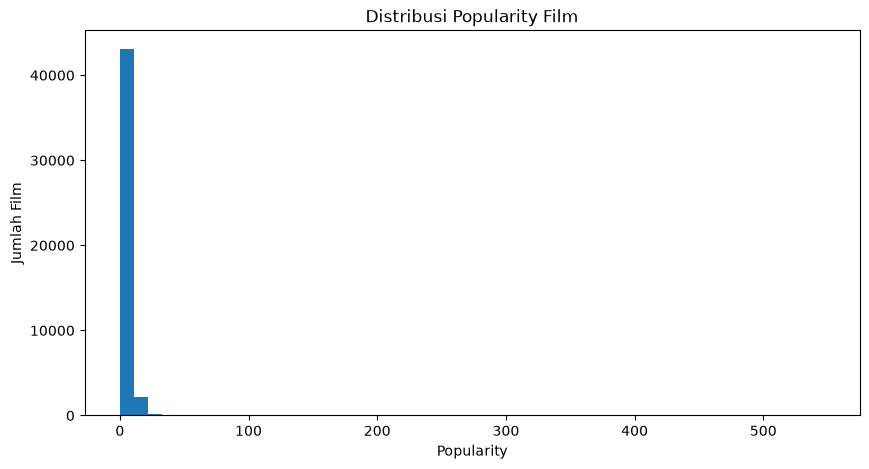

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(popularity_numeric.dropna(), bins=50)
plt.title('Distribusi Popularity Film')
plt.xlabel('Popularity')
plt.ylabel('Jumlah Film')
plt.show()

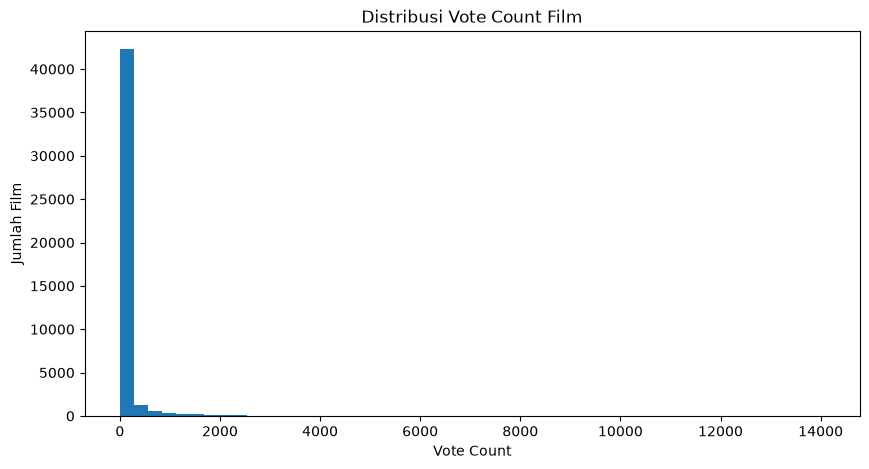

In [27]:
plt.figure(figsize=(10, 5))
plt.hist(df_movies['vote_count'].dropna(), bins=50)
plt.title('Distribusi Vote Count Film')
plt.xlabel('Vote Count')
plt.ylabel('Jumlah Film')
plt.show()

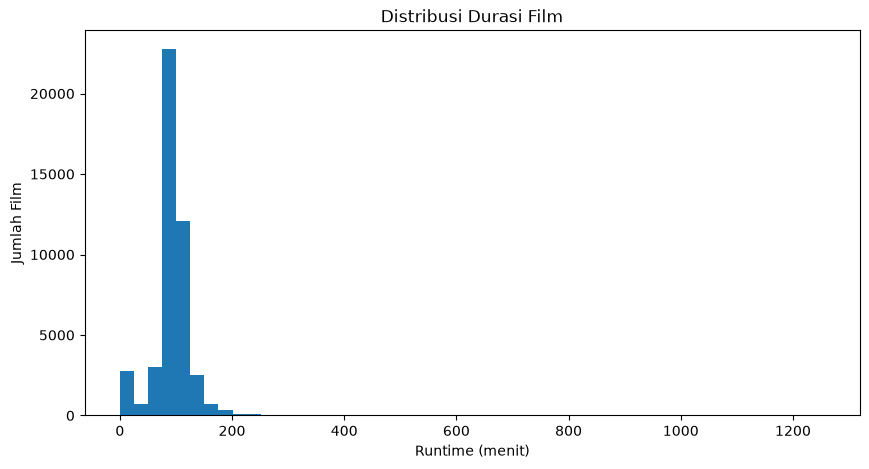

In [28]:
plt.figure(figsize=(10, 5))
plt.hist(df_movies['runtime'].dropna(), bins=50)
plt.title('Distribusi Durasi Film')
plt.xlabel('Runtime (menit)')
plt.ylabel('Jumlah Film')
plt.show()

C:\Users\THINKPAD\AppData\Local\Temp\ipykernel_12100\1719399833.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_movies['runtime'].dropna(), vert=False)


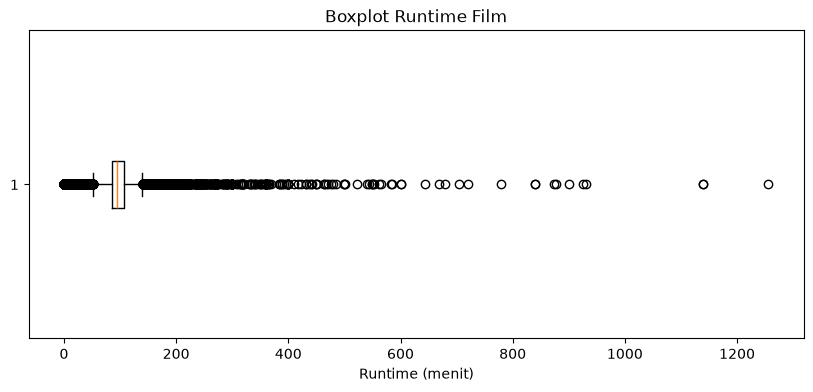

In [29]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_movies['runtime'].dropna(), vert=False)
plt.title('Boxplot Runtime Film')
plt.xlabel('Runtime (menit)')
plt.show()

In [30]:
runtime_extreme = df_movies[
    df_movies['runtime'] > 300
][['title', 'runtime', 'release_date']].sort_values(
    by='runtime', ascending=False
)

runtime_extreme.head(20)

,title,runtime,release_date
24178,Centennial,1256.0,1978-10-01
19965,Jazz,1140.0,2001-01-09
40938,Baseball,1140.0,1994-09-18
13767,Berlin Alexanderplatz,931.0,1980-08-28
13953,Heimat: A Chronicle of Germany,925.0,1984-09-16
27855,The Story of Film: An Odyssey,900.0,2011-09-03
26682,Taken,877.0,2002-12-02
19158,The War,874.0,2007-09-23
34667,The Roosevelts: An Intimate History,840.0,2014-09-15
34732,Seventeen Moments in Spring,840.0,1973-01-01


In [31]:
runtime_zero = df_movies[
    df_movies['runtime'] <= 0
][['title', 'runtime', 'release_date']]

runtime_zero.head(20)

,title,runtime,release_date
222,Dream Man,0.0,1995-01-01
224,Destiny Turns on the Radio,0.0,1995-04-28
398,Dos Crímenes,0.0,1995-05-26
554,"The Beans of Egypt, Maine",0.0,1994-01-01
667,The Run of the Country,0.0,1995-09-22
679,Under The Domim Tree,0.0,1994-01-01
685,To Cross the Rubicon,0.0,1991-01-01
776,The Old Lady Who Walked in the Sea,0.0,1991-09-18
792,A Boy Called Hate,0.0,1996-05-22
832,Mille bolle blu,0.0,1993-01-01


In [32]:
print("Runtime kosong:", df_movies['runtime'].isna().sum())
print("Runtime 0 atau negatif:", (df_movies['runtime'] <= 0).sum())
print("Runtime di atas 300 menit:", (df_movies['runtime'] > 300).sum())

Runtime kosong: 263
Runtime 0 atau negatif: 1558
Runtime di atas 300 menit: 108


### 1.6 Pemeriksaan Tahun Rilis dan Rating

Tanggal rilis diubah sementara menjadi format tanggal agar tahun rilis dapat diperiksa. Rating dan jumlah vote juga diamati untuk mengetahui apakah terdapat nilai yang perlu dipertimbangkan saat menentukan data yang layak digunakan.

In [33]:
release_date = pd.to_datetime(df_movies['release_date'], errors='coerce')

release_year = release_date.dt.year

print("Tanggal rilis kosong/tidak valid:", release_date.isna().sum())
print("Tahun paling awal:", release_year.min())
print("Tahun paling akhir:", release_year.max())

Tanggal rilis kosong/tidak valid: 90
Tahun paling awal: 1874.0
Tahun paling akhir: 2020.0


In [34]:
df_movies.loc[
    release_year < 1900,
    ['title', 'release_date']
].sort_values('release_date').head(20)

,title,release_date
34940,Passage of Venus,1874-12-09
34937,Sallie Gardner at a Gallop,1878-06-14
41602,Buffalo Running,1883-11-19
34933,Man Walking Around a Corner,1887-08-18
34934,Accordion Player,1888-01-01
34938,Traffic Crossing Leeds Bridge,1888-10-15
34939,London's Trafalgar Square,1890-01-01
41194,Mosquinha,1890-03-09
34935,"Monkeyshines, No. 1",1890-11-21
34936,"Monkeyshines, No. 2",1890-11-21


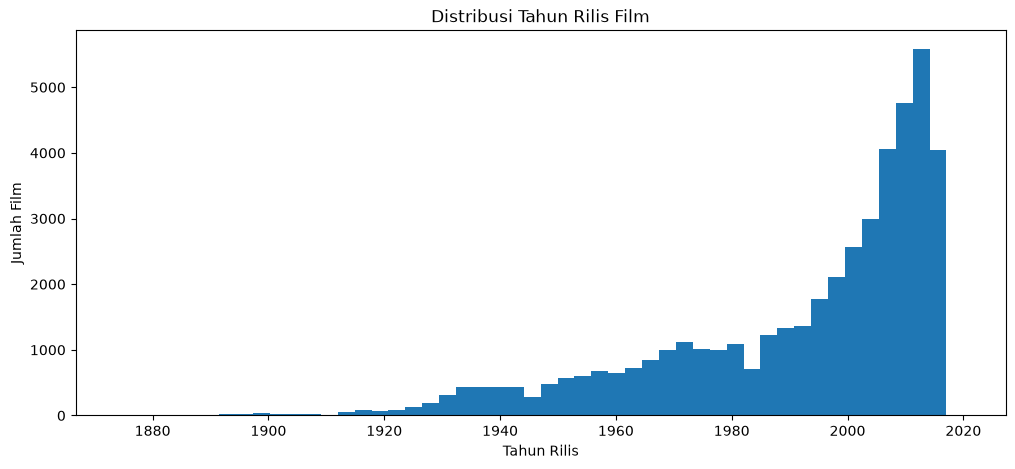

In [35]:
plt.figure(figsize=(12, 5))
plt.hist(release_year.dropna(), bins=50)
plt.title('Distribusi Tahun Rilis Film')
plt.xlabel('Tahun Rilis')
plt.ylabel('Jumlah Film')
plt.show()

In [36]:
film_per_dekade = (release_year.dropna() // 10 * 10).astype(int)

film_per_dekade.value_counts().sort_index()

release_date
1870        2
1880        4
1890       75
1900       87
1910      176
1920      432
1930     1317
1940     1494
1950     2080
1960     2622
1970     3472
1980     3931
1990     5677
2000    11207
2010    12799
2020        1
Name: count, dtype: int64

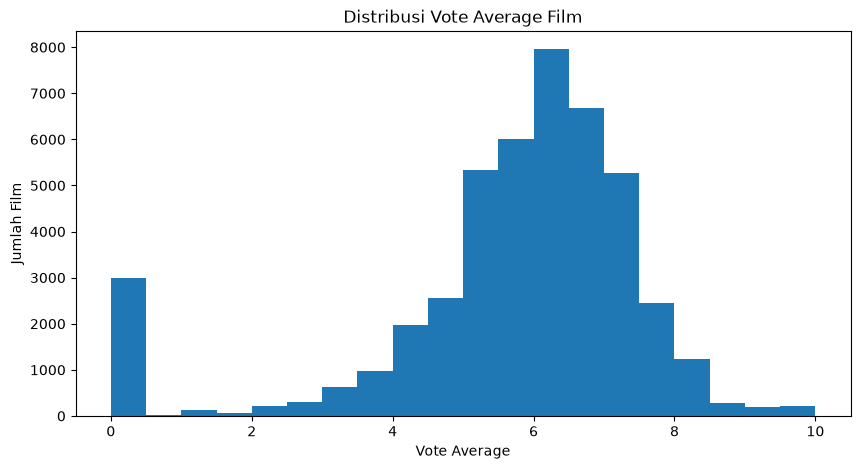

In [37]:
plt.figure(figsize=(10, 5))
plt.hist(df_movies['vote_average'].dropna(), bins=20)
plt.title('Distribusi Vote Average Film')
plt.xlabel('Vote Average')
plt.ylabel('Jumlah Film')
plt.show()

In [38]:
rating_zero = df_movies[df_movies['vote_average'] == 0]

print("Film dengan rating 0:", len(rating_zero))
print("Rating 0 dan vote_count 0:",
      len(rating_zero[rating_zero['vote_count'] == 0]))
print("Rating 0 tetapi vote_count > 0:",
      len(rating_zero[rating_zero['vote_count'] > 0]))

Film dengan rating 0: 2998
Rating 0 dan vote_count 0: 2899
Rating 0 tetapi vote_count > 0: 99


In [39]:
rating_zero_with_votes = df_movies[
    (df_movies['vote_average'] == 0) &
    (df_movies['vote_count'] > 0)
][['title', 'vote_average', 'vote_count']]

rating_zero_with_votes.head(20)

,title,vote_average,vote_count
554,"The Beans of Egypt, Maine",0.0,1.0
1371,Inside,0.0,1.0
1564,Alive and Kicking,0.0,1.0
12274,Joe and Max,0.0,1.0
13226,Pete Seeger: The Power of Song,0.0,1.0
14171,Mr. Robinson Crusoe,0.0,1.0
14804,Me and Him,0.0,1.0
15514,Mammy,0.0,1.0
15748,Pride of the Marines,0.0,2.0
16653,Girls About Town,0.0,1.0


### 1.7 Pemeriksaan Genre dan Konsistensi ID

Genre diperiksa untuk memahami jumlah genre per film dan daftar genre yang muncul pada dataset. ID film juga diperiksa untuk mengetahui apakah terdapat ID kosong, berulang, atau memiliki isi data yang berbeda.

In [40]:
import ast

def hitung_genre(value):
    try:
        genre_list = ast.literal_eval(value)
        return len(genre_list) if isinstance(genre_list, list) else 0
    except:
        return 0

jumlah_genre = df_movies['genres'].apply(hitung_genre)

jumlah_genre.value_counts().sort_index()

genres
0     2442
1    14559
2    14480
3     9586
4     3380
5      835
6      157
7       24
8        3
Name: count, dtype: int64

In [41]:
df_movies.loc[
    jumlah_genre == 0,
    ['title', 'release_date', 'vote_average', 'vote_count', 'popularity']
].head(20)

,title,release_date,vote_average,vote_count,popularity
55,Kids of the Round Table,1997-07-08,3.0,1.0,0.307075
83,Last Summer in the Hamptons,1995-11-22,0.0,0.0,0.531159
126,Jupiter's Wife,1995-01-01,0.0,0.0,0.001178
137,Target,1995-08-01,0.0,0.0,0.001205
390,Desert Winds,1997-12-31,0.0,0.0,0.251223
398,Dos Crímenes,1995-05-26,5.0,1.0,0.233376
401,Federal Hill,1995-02-24,5.0,2.0,0.100685
554,"The Beans of Egypt, Maine",1994-01-01,0.0,1.0,0.38247
595,A Great Day in Harlem,1994-09-27,7.0,2.0,0.076352
614,A Modern Affair,1996-09-06,5.0,1.0,0.173207


In [42]:
all_genres = set()

for value in df_movies['genres'].dropna():
    try:
        genre_list = ast.literal_eval(value)
        for genre in genre_list:
            all_genres.add(genre['name'])
    except:
        pass

sorted(all_genres)

['Action',
 'Adventure',
 'Animation',
 'Aniplex',
 'BROSTA TV',
 'Carousel Productions',
 'Comedy',
 'Crime',
 'Documentary',
 'Drama',
 'Family',
 'Fantasy',
 'Foreign',
 'GoHands',
 'History',
 'Horror',
 'Mardock Scramble Production Committee',
 'Music',
 'Mystery',
 'Odyssey Media',
 'Pulser Productions',
 'Rogue State',
 'Romance',
 'Science Fiction',
 'Sentai Filmworks',
 'TV Movie',
 'Telescene Film Group Productions',
 'The Cartel',
 'Thriller',
 'Vision View Entertainment',
 'War',
 'Western']

In [43]:
genre_anomali = [
    'Aniplex',
    'BROSTA TV',
    'Carousel Productions',
    'GoHands',
    'Mardock Scramble Production Committee',
    'Odyssey Media',
    'Pulser Productions',
    'Rogue State',
    'Sentai Filmworks',
    'Telescene Film Group Productions',
    'The Cartel',
    'Vision View Entertainment'
]

df_movies.loc[
    df_movies['genres'].apply(
        lambda x: any(
            g['name'] in genre_anomali
            for g in ast.literal_eval(x)
        ) if pd.notna(x) else False
    ),
    ['title', 'genres', 'release_date']
]

,title,genres,release_date
19730,NaN,"[{'name': 'Carousel Productions', 'id': 11176}...",1
29503,NaN,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...",12
35587,NaN,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...",22


In [44]:
print("Jumlah baris:", len(df_movies))
print("Jumlah ID unik:", df_movies['id'].nunique())
print("Jumlah ID kosong:", df_movies['id'].isna().sum())
print("Jumlah ID duplikat:", df_movies['id'].duplicated().sum())

Jumlah baris: 45466
Jumlah ID unik: 45436
Jumlah ID kosong: 0
Jumlah ID duplikat: 30


In [45]:
duplicate_id_counts = df_movies[
    df_movies['id'].duplicated(keep=False)
]['id'].value_counts()

duplicate_id_counts.head(15)

id
141971    3
105045    2
132641    2
22649     2
84198     2
10991     2
110428    2
15028     2
12600     2
109962    2
4912      2
5511      2
23305     2
69234     2
14788     2
Name: count, dtype: int64

In [46]:
df_movies[df_movies['id'] == '141971']

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
13261,False,NaN,0,"[{'id': 53, 'name': 'Thriller'}, {'id': 9648, ...",NaN,141971,tt1180333,fi,Blackout,Recovering from a nail gun shot to the head an...,...,2008-12-26,0.0,108.0,"[{'iso_639_1': 'fi', 'name': 'suomi'}]",Released,Which one is the first to return - memory or t...,Blackout,False,6.7,3.0
13375,False,NaN,0,"[{'id': 53, 'name': 'Thriller'}, {'id': 9648, ...",NaN,141971,tt1180333,fi,Blackout,Recovering from a nail gun shot to the head an...,...,2008-12-26,0.0,108.0,"[{'iso_639_1': 'fi', 'name': 'suomi'}]",Released,Which one is the first to return - memory or t...,Blackout,False,6.7,3.0
16764,False,NaN,0,"[{'id': 53, 'name': 'Thriller'}, {'id': 9648, ...",NaN,141971,tt1180333,fi,Blackout,Recovering from a nail gun shot to the head an...,...,2008-12-26,0.0,108.0,"[{'iso_639_1': 'fi', 'name': 'suomi'}]",Released,Which one is the first to return - memory or t...,Blackout,False,6.7,3.0


In [47]:
duplicate_rows = df_movies[
    df_movies['id'].duplicated(keep=False)
]

print("Baris dengan ID berulang:", len(duplicate_rows))
print("Duplikat identik sepenuhnya:",
      duplicate_rows.duplicated().sum())

Baris dengan ID berulang: 59
Duplikat identik sepenuhnya: 13


In [48]:
duplicate_ids = df_movies[
    df_movies['id'].duplicated(keep=False)
]

variation = duplicate_ids.groupby('id').apply(
    lambda group: group.drop_duplicates().shape[0]
)

different_ids = variation[variation > 1]

print("ID yang memiliki isi berbeda:", len(different_ids))
print(different_ids)

ID yang memiliki isi berbeda: 17
id
10991     2
109962    2
110428    2
12600     2
13209     2
132641    2
14788     2
15028     2
159849    2
22649     2
265189    2
4912      2
69234     2
77221     2
84198     2
97995     2
99080     2
dtype: int64


In [49]:
check_columns = [
    'id',
    'title',
    'original_title',
    'release_date',
    'genres',
    'runtime',
    'vote_average',
    'vote_count',
    'popularity'
]

df_movies[df_movies['id'].isin(different_ids.index)][check_columns].sort_values('id')

,id,title,original_title,release_date,genres,runtime,vote_average,vote_count,popularity
4114,10991,Pokémon: Spell of the Unknown,Pokémon 3: The Movie,2000-07-08,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",93.0,6.0,143.0,10.264597
44821,10991,Pokémon: Spell of the Unknown,Pokémon 3: The Movie,2000-07-08,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",93.0,6.0,144.0,6.480376
5710,109962,Rich and Famous,Rich and Famous,1981-09-23,"[{'id': 18, 'name': 'Drama'}]",115.0,4.9,7.0,12.180836
20899,109962,Rich and Famous,Rich and Famous,1981-09-23,"[{'id': 18, 'name': 'Drama'}]",115.0,4.9,7.0,10.396878
4356,110428,Camille Claudel 1915,Camille Claudel 1915,2013-03-13,"[{'id': 18, 'name': 'Drama'}]",95.0,7.0,20.0,0.134014
23534,110428,Camille Claudel 1915,Camille Claudel 1915,2013-03-13,"[{'id': 18, 'name': 'Drama'}]",95.0,7.0,20.0,0.110065
5535,12600,Pokémon 4Ever: Celebi - Voice of the Forest,劇場版ポケットモンスター セレビィ 時を越えた遭遇（であい）,2001-07-06,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",75.0,5.7,82.0,7.072301
44826,12600,Pokémon 4Ever: Celebi - Voice of the Forest,劇場版ポケットモンスター セレビィ 時を越えた遭遇（であい）,2001-07-06,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",75.0,5.7,82.0,6.080108
11342,13209,Offside,Offside,2006-05-26,"[{'id': 18, 'name': 'Drama'}, {'id': 35, 'name...",93.0,6.7,27.0,1.52896
15765,13209,Offside,Offside,2006-05-26,"[{'id': 18, 'name': 'Drama'}, {'id': 35, 'name...",93.0,6.7,27.0,1.529879


In [50]:
for film_id in different_ids.index:
    group = df_movies[df_movies['id'] == film_id]

    different_columns = [
        col for col in group.columns
        if group[col].nunique(dropna=False) > 1
    ]

    print(f"ID {film_id}: {different_columns}")

ID 10991: ['popularity', 'vote_count']
ID 109962: ['popularity']
ID 110428: ['popularity']
ID 12600: ['popularity']
ID 13209: ['popularity']
ID 132641: ['popularity']
ID 14788: ['popularity']
ID 15028: ['popularity', 'vote_count']
ID 159849: ['popularity']
ID 22649: ['popularity']
ID 265189: ['popularity']
ID 4912: ['popularity']
ID 69234: ['popularity']
ID 77221: ['popularity']
ID 84198: ['popularity']
ID 97995: ['popularity']
ID 99080: ['popularity']


### 1.8 Pemeriksaan Status dan Kelengkapan Metadata

Bagian ini melihat status rilis film, ketersediaan genre, judul, dan atribut utama lainnya. Hasil pemeriksaan menjadi bahan pertimbangan dalam menentukan kriteria film yang akan dipertahankan.

In [51]:
df_movies['status'].value_counts(dropna=False)

status
Released           45014
Rumored              230
Post Production       98
NaN                   87
In Production         20
Planned               15
Canceled               2
Name: count, dtype: int64

In [52]:
df_movies[df_movies['status'] != 'Released'][
    ['title', 'status', 'vote_average', 'vote_count', 'popularity']
].head(15)

,title,status,vote_average,vote_count,popularity
189,The Show,NaN,5.3,2.0,0.159596
682,Butterfly Kiss,Rumored,7.4,5.0,0.877853
767,The Gate of Heavenly Peace,NaN,6.7,3.0,0.10705
775,A Very Natural Thing,Rumored,6.3,3.0,0.147662
1032,The Sunchaser,Rumored,6.1,8.0,2.35809
1384,Meet Wally Sparks,NaN,5.3,10.0,0.576741
1478,The War at Home,Rumored,6.9,7.0,0.893464
1513,Love Serenade,Rumored,6.0,4.0,0.881482
1607,"I Love You, I Love You Not",Rumored,5.0,10.0,0.380405
1763,Go Now,Rumored,0.0,0.0,0.153884


In [53]:
non_released = df_movies[df_movies['status'] != 'Released']

print("Total film non-Released:", len(non_released))
print("Memiliki vote (> 0):", (non_released['vote_count'] > 0).sum())
print("Tidak memiliki vote (0):", (non_released['vote_count'] == 0).sum())
print("Vote kosong (NaN):", non_released['vote_count'].isna().sum())

Total film non-Released: 452
Memiliki vote (> 0): 390
Tidak memiliki vote (0): 56
Vote kosong (NaN): 6


In [54]:
non_released = df_movies[df_movies['status'] != 'Released']

genre_available = non_released['genres'].apply(
    lambda x: isinstance(x, str) and x.strip() != '[]'
)

print("Non-Released dengan data genre:", genre_available.sum())
print("Non-Released tanpa data genre:", (~genre_available).sum())

Non-Released dengan data genre: 394
Non-Released tanpa data genre: 58


In [55]:
df_movies[df_movies['title'].isna()][
    ['id', 'original_title', 'release_date', 'genres',
     'runtime', 'vote_average', 'vote_count', 'popularity']
]

,id,original_title,release_date,genres,runtime,vote_average,vote_count,popularity
19729,82663,Midnight Man,NaN,"[{'id': 28, 'name': 'Action'}, {'id': 53, 'nam...",NaN,NaN,NaN,NaN
19730,1997-08-20,"[{'iso_639_1': 'en', 'name': 'English'}]",1,"[{'name': 'Carousel Productions', 'id': 11176}...",NaN,NaN,NaN,NaN
29502,122662,マルドゥック・スクランブル 排気,NaN,"[{'id': 16, 'name': 'Animation'}, {'id': 878, ...",NaN,NaN,NaN,NaN
29503,2012-09-29,"[{'iso_639_1': 'ja', 'name': '日本語'}]",12,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...",NaN,NaN,NaN,NaN
35586,249260,Avalanche Sharks,NaN,"[{'id': 10770, 'name': 'TV Movie'}, {'id': 28,...",NaN,NaN,NaN,NaN
35587,2014-01-01,"[{'iso_639_1': 'en', 'name': 'English'}]",22,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...",NaN,NaN,NaN,Beware Of Frost Bites


In [56]:
df_movies.loc[[19729, 29502, 35586]].T

,19729,29502,35586
adult,False,False,False
belongs_to_collection,NaN,"{'id': 122661, 'name': 'Mardock Scramble Colle...",NaN
budget,0,0,0
genres,"[{'id': 28, 'name': 'Action'}, {'id': 53, 'nam...","[{'id': 16, 'name': 'Animation'}, {'id': 878, ...","[{'id': 10770, 'name': 'TV Movie'}, {'id': 28,..."
homepage,NaN,http://m-scramble.jp/exhaust/,NaN
id,82663,122662,249260
imdb_id,tt0113002,tt2423504,tt2622826
original_language,en,ja,en
original_title,Midnight Man,マルドゥック・スクランブル 排気,Avalanche Sharks
overview,British soldiers force a recently captured IRA...,Third film of the Mardock Scramble series.,A group of skiers are terrorized during spring...


In [57]:
main_features = [
    'title',
    'genres',
    'popularity',
    'vote_average',
    'vote_count',
    'runtime',
    'release_date'
]

df_movies[main_features].isna().sum()

title             6
genres            0
popularity        5
vote_average      6
vote_count        6
runtime         263
release_date     87
dtype: int64

In [58]:
main_features = [
    'title',
    'popularity',
    'vote_average',
    'vote_count',
    'runtime',
    'release_date'
]

missing_per_movie = df_movies[main_features].isna().any(axis=1)

print("Film dengan minimal 1 missing value:",
      missing_per_movie.sum())

print("Film tanpa missing value pada fitur utama:",
      (~missing_per_movie).sum())

Film dengan minimal 1 missing value: 336
Film tanpa missing value pada fitur utama: 45130


In [59]:
missing_pattern = (
    df_movies[main_features]
    .isna()
    .apply(lambda row: ', '.join(row.index[row]), axis=1)
)

missing_pattern[missing_pattern != ''].value_counts()

runtime                                                               246
release_date                                                           73
runtime, release_date                                                  11
title, popularity, vote_average, vote_count, runtime, release_date      3
title, popularity, vote_average, vote_count, runtime                    2
title, vote_average, vote_count, runtime                                1
Name: count, dtype: int64

In [60]:
import ast
from collections import Counter

# Daftar genre valid
valid_genres = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Documentary', 'Drama', 'Family', 'Fantasy', 'Foreign',
    'History', 'Horror', 'Music', 'Mystery', 'Romance',
    'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western'
]

genre_counter = Counter()

for genre_data in df_movies['genres']:
    try:
        genres = ast.literal_eval(genre_data)

        for genre in genres:
            if genre['name'] in valid_genres:
                genre_counter[genre['name']] += 1

    except (ValueError, SyntaxError, TypeError):
        continue

genre_counts = pd.Series(genre_counter).sort_values(ascending=False)

print("Jumlah genre ditemukan:", len(genre_counts))
display(genre_counts)

Jumlah genre ditemukan: 20


Drama              20265
Comedy             13182
Thriller            7624
Romance             6735
Action              6596
Horror              4673
Crime               4307
Documentary         3932
Adventure           3496
Science Fiction     3049
Family              2770
Mystery             2467
Fantasy             2313
Animation           1935
Foreign             1622
Music               1598
History             1398
War                 1323
Western             1042
TV Movie             767
dtype: int64

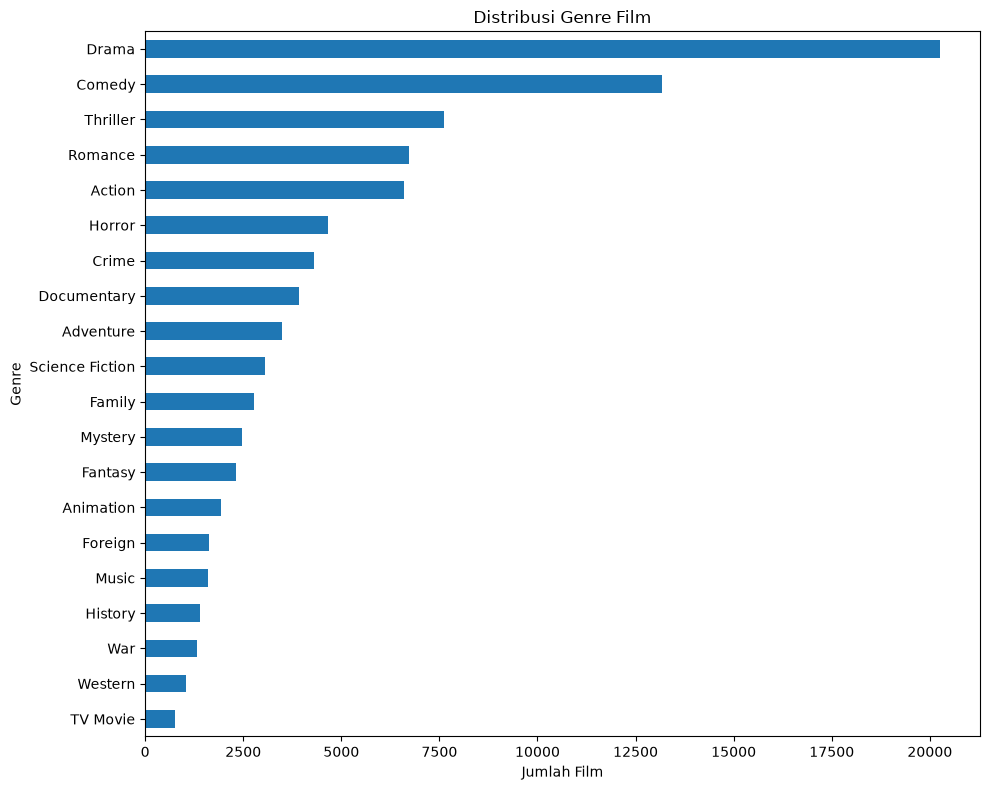

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

genre_counts.sort_values().plot(kind='barh')

plt.title('Distribusi Genre Film')
plt.xlabel('Jumlah Film')
plt.ylabel('Genre')
plt.tight_layout()

plt.show()

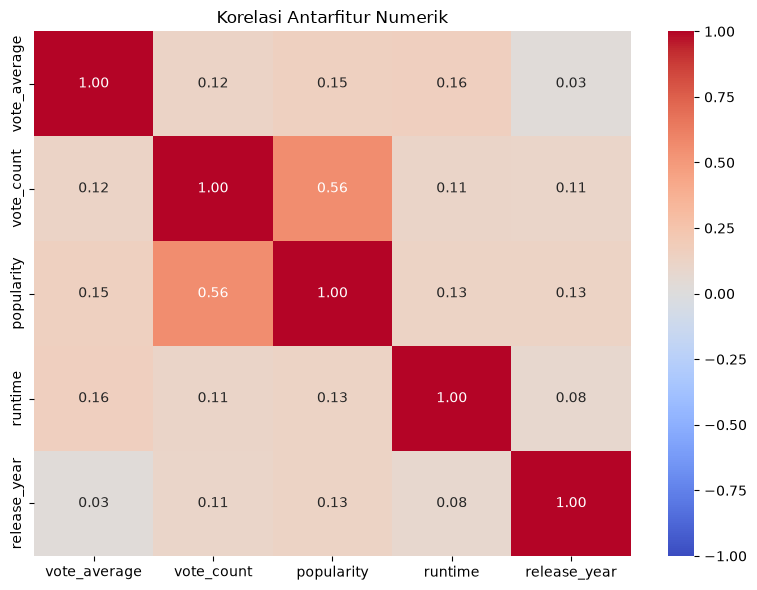

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_data = pd.DataFrame({
    'vote_average': df_movies['vote_average'],
    'vote_count': df_movies['vote_count'],
    'popularity': popularity_numeric,
    'runtime': df_movies['runtime'],
    'release_year': release_year
})

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Korelasi Antarfitur Numerik')
plt.tight_layout()
plt.show()

## 2. Data Cleaning

Pada tahap ini dibuat salinan dataset agar data mentah tetap tersimpan. Pembersihan dilakukan secara bertahap, meliputi penghapusan duplikat identik, pemeriksaan ID tidak valid, penanganan ID berulang, dan pemeriksaan nilai kosong atau tidak masuk akal pada fitur utama.

preprocessing

In [63]:
df_movies_clean = df_movies.copy()

print("Jumlah data awal:", df_movies_clean.shape)
print("Dataset berhasil disalin.")

Jumlah data awal: (45466, 24)
Dataset berhasil disalin.


### 2.1 Menghapus Duplikat dan Memeriksa ID

Baris yang identik sepenuhnya dihapus. Selanjutnya, ID film diperiksa agar hanya data dengan ID valid yang dipertahankan. Untuk ID yang berulang tetapi memiliki isi berbeda, data dibandingkan sebelum dipilih satu baris yang paling mewakili.

In [64]:
# Cek jumlah duplikat identik
jumlah_duplikat = df_movies_clean.duplicated().sum()

# Hapus duplikat identik
df_movies_clean = df_movies_clean.drop_duplicates().copy()

print("Duplikat identik ditemukan:", jumlah_duplikat)
print("Duplikat identik dihapus:", jumlah_duplikat)
print("Ukuran dataset setelah cleaning:", df_movies_clean.shape)

Duplikat identik ditemukan: 13
Duplikat identik dihapus: 13
Ukuran dataset setelah cleaning: (45453, 24)


In [65]:
# Mendeteksi ID film yang bukan angka
id_numeric = pd.to_numeric(df_movies_clean['id'], errors='coerce')

# Mengambil baris dengan ID tidak valid
invalid_id_rows = df_movies_clean[id_numeric.isna()]

print("Jumlah ID tidak valid:", len(invalid_id_rows))

display(
    invalid_id_rows[
        ['id', 'title', 'original_title', 'release_date', 'genres']
    ]
)

Jumlah ID tidak valid: 3


,id,title,original_title,release_date,genres
19730,1997-08-20,NaN,"[{'iso_639_1': 'en', 'name': 'English'}]",1,"[{'name': 'Carousel Productions', 'id': 11176}..."
29503,2012-09-29,NaN,"[{'iso_639_1': 'ja', 'name': '日本語'}]",12,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go..."
35587,2014-01-01,NaN,"[{'iso_639_1': 'en', 'name': 'English'}]",22,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam..."


In [66]:
# Identifikasi ID yang valid dan tidak valid
id_numeric = pd.to_numeric(df_movies_clean['id'], errors='coerce')

# Simpan baris yang rusak untuk dokumentasi
df_invalid_csv_rows = df_movies_clean[id_numeric.isna()].copy()

# Hapus baris dengan ID tidak valid
df_movies_clean = df_movies_clean[id_numeric.notna()].copy()

print("Baris CSV rusak yang dihapus:", len(df_invalid_csv_rows))
print("Jumlah data tersisa:", df_movies_clean.shape)

Baris CSV rusak yang dihapus: 3
Jumlah data tersisa: (45450, 24)


In [67]:
# Menghitung frekuensi kemunculan setiap ID
id_counts = df_movies_clean['id'].value_counts()

# Mengambil ID yang muncul lebih dari satu kali
duplicate_ids = id_counts[id_counts > 1]

print("Jumlah ID film yang berulang:", len(duplicate_ids))
print("Jumlah baris yang terlibat dalam ID berulang:", duplicate_ids.sum())
print("\nID yang paling sering muncul:")
display(duplicate_ids.head(10))

Jumlah ID film yang berulang: 17
Jumlah baris yang terlibat dalam ID berulang: 34

ID yang paling sering muncul:


id
132641    2
22649     2
84198     2
10991     2
110428    2
15028     2
12600     2
109962    2
4912      2
69234     2
Name: count, dtype: int64

In [68]:
# Memeriksa perbedaan data pada setiap ID yang berulang
for movie_id in duplicate_ids.index:
    group = df_movies_clean[df_movies_clean['id'] == movie_id]

    # Ambil kolom yang memiliki nilai berbeda
    different_columns = group.columns[
        group.nunique(dropna=False) > 1
    ]

    print(f"\nID Film: {movie_id}")
    display(group[different_columns])


ID Film: 132641


,popularity
838,0.096079
30001,0.619388



ID Film: 22649


,popularity
949,1.914697
15074,2.411191



ID Film: 84198


,popularity
2564,0.501046
21116,1.673307


... (24 outputs left out)


ID Film: 99080


,popularity
16167,0.002362
38871,0.002362



ID Film: 265189


,popularity
24164,12.165685
45265,12.165685


In [69]:
# Konversi vote_count dan popularity ke numerik untuk keperluan sorting
df_movies_clean['vote_count'] = pd.to_numeric(
    df_movies_clean['vote_count'], errors='coerce'
)

df_movies_clean['popularity'] = pd.to_numeric(
    df_movies_clean['popularity'], errors='coerce'
)

# Urutkan: vote_count terbesar, lalu popularity terbesar
df_movies_clean = df_movies_clean.sort_values(
    by=['vote_count', 'popularity'],
    ascending=False
)

# Pertahankan satu record untuk setiap ID
df_movies_clean = df_movies_clean.drop_duplicates(
    subset='id', keep='first'
).copy()

print("Jumlah data setelah deduplikasi ID:", df_movies_clean.shape)
print("Jumlah ID unik:", df_movies_clean['id'].nunique())
print("ID duplikat tersisa:", df_movies_clean['id'].duplicated().sum())

Jumlah data setelah deduplikasi ID: (45433, 24)
Jumlah ID unik: 45433
ID duplikat tersisa: 0


### 2.2 Memeriksa dan Menangani Missing Value

Kolom utama diperiksa kembali setelah penanganan duplikasi. Judul yang kosong diisi menggunakan `original_title` jika tersedia. Runtime bernilai nol atau negatif dianggap tidak valid dan diubah menjadi missing value agar dapat ditangani melalui proses filtering.

In [70]:
# Kolom utama yang direncanakan untuk sistem rekomendasi
main_features = [
    'title',
    'genres',
    'popularity',
    'vote_average',
    'vote_count',
    'runtime',
    'release_date'
]

missing_after_dedup = df_movies_clean[main_features].isna().sum()

print("Missing value setelah cleaning duplikat:\n")
display(missing_after_dedup[missing_after_dedup > 0])

print("\nTotal baris dataset saat ini:", len(df_movies_clean))

Missing value setelah cleaning duplikat:



title             3
popularity        3
vote_average      3
vote_count        3
runtime         260
release_date     87
dtype: int64


Total baris dataset saat ini: 45433


In [71]:
# Cari film yang missing pada popularity, vote_average, atau vote_count
missing_important = df_movies_clean[
    df_movies_clean[['popularity', 'vote_average', 'vote_count']].isna().any(axis=1)
]

display(
    missing_important[
        ['id', 'title', 'original_title', 'popularity',
         'vote_average', 'vote_count', 'runtime', 'release_date', 'genres']
    ]
)

,id,title,original_title,popularity,vote_average,vote_count,runtime,release_date,genres
19729,82663,NaN,Midnight Man,NaN,NaN,NaN,NaN,NaN,"[{'id': 28, 'name': 'Action'}, {'id': 53, 'nam..."
29502,122662,NaN,マルドゥック・スクランブル 排気,NaN,NaN,NaN,NaN,NaN,"[{'id': 16, 'name': 'Animation'}, {'id': 878, ..."
35586,249260,NaN,Avalanche Sharks,NaN,NaN,NaN,NaN,NaN,"[{'id': 10770, 'name': 'TV Movie'}, {'id': 28,..."


In [72]:
# Isi title yang kosong menggunakan original_title
missing_title = df_movies_clean['title'].isna()

df_movies_clean.loc[missing_title, 'title'] = (
    df_movies_clean.loc[missing_title, 'original_title']
)

print("Jumlah title kosong setelah perbaikan:",
      df_movies_clean['title'].isna().sum())

display(
    df_movies_clean.loc[missing_title, ['title', 'original_title']]
)

Jumlah title kosong setelah perbaikan: 0


,title,original_title
19729,Midnight Man,Midnight Man
29502,マルドゥック・スクランブル 排気,マルドゥック・スクランブル 排気
35586,Avalanche Sharks,Avalanche Sharks


In [73]:
# Memeriksa film yang tidak memiliki runtime
missing_runtime = df_movies_clean[df_movies_clean['runtime'].isna()]

print("Jumlah film tanpa runtime:", len(missing_runtime))

display(
    missing_runtime[
        ['id', 'title', 'vote_average', 'vote_count',
         'popularity', 'release_date', 'genres']
    ].head(15)
)

Jumlah film tanpa runtime: 260


,id,title,vote_average,vote_count,popularity,release_date,genres
43596,439998,Omicidio all'italiana,6.3,69.0,2.962735,2017-03-02,"[{'id': 35, 'name': 'Comedy'}]"
35491,298722,Soap Opera,5.3,46.0,2.012232,2014-10-23,"[{'id': 35, 'name': 'Comedy'}]"
31556,270479,Ammutta muddica al cinema,6.3,43.0,1.793601,2013-10-16,"[{'id': 35, 'name': 'Comedy'}]"
41922,392832,Nemiche per la pelle,5.7,31.0,1.504535,2016-04-14,"[{'id': 35, 'name': 'Comedy'}]"
30782,60046,Il vigile,7.8,29.0,0.312507,1960-01-01,"[{'id': 35, 'name': 'Comedy'}]"
25911,56551,Maledetto il giorno che t'ho incontrato,6.4,28.0,1.100118,1992-01-31,[]
42149,428645,Eu Fico Loko,8.3,22.0,1.948382,2017-01-12,"[{'id': 35, 'name': 'Comedy'}]"
40725,175791,Ci vuole un gran fisico,4.7,18.0,0.684208,2013-03-10,"[{'id': 35, 'name': 'Comedy'}]"
31587,58714,Due partite,6.6,15.0,0.964569,2009-01-01,"[{'id': 18, 'name': 'Drama'}]"
31358,332354,Rey gitano,4.2,13.0,0.772191,2015-07-17,"[{'id': 35, 'name': 'Comedy'}]"


In [74]:
# Film dengan runtime kosong yang memiliki minimal 50 vote
missing_runtime_vote50 = missing_runtime[
    missing_runtime['vote_count'] >= 50
]

print("Runtime kosong:", len(missing_runtime))
print("Runtime kosong dan vote_count >= 50:", len(missing_runtime_vote50))

Runtime kosong: 260
Runtime kosong dan vote_count >= 50: 1


In [75]:
# Film dengan runtime 0 atau negatif
invalid_runtime = df_movies_clean[
    df_movies_clean['runtime'].notna() &
    (df_movies_clean['runtime'] <= 0)
]

# Dari film tersebut, cek yang memenuhi vote_count >= 50
invalid_runtime_vote50 = invalid_runtime[
    invalid_runtime['vote_count'] >= 50
]

print("Runtime 0 atau negatif:", len(invalid_runtime))
print("Runtime 0/negatif dengan vote_count >= 50:", len(invalid_runtime_vote50))

Runtime 0 atau negatif: 1558
Runtime 0/negatif dengan vote_count >= 50: 46


In [76]:
# Ubah runtime 0 atau negatif menjadi missing value (NaN)
df_movies_clean.loc[
    df_movies_clean['runtime'] <= 0,
    'runtime'
] = np.nan

print("Runtime tidak valid sudah ditandai sebagai missing.")
print("Total missing runtime sekarang:",
      df_movies_clean['runtime'].isna().sum())

Runtime tidak valid sudah ditandai sebagai missing.
Total missing runtime sekarang: 1818


### 2.3 Memeriksa Genre dan Menentukan Kriteria Filtering

Genre yang kosong atau tidak dapat dibaca dianggap tidak memenuhi syarat. Dataset kemudian disaring menggunakan kriteria:
- `vote_count` minimal 50.
- `runtime` tersedia dan lebih dari 0.
- Genre tersedia.
- `release_date` tersedia.

Kriteria ini digunakan untuk mempertahankan film yang memiliki informasi cukup untuk membentuk fitur rekomendasi.

In [77]:
import ast

def cek_genre_kosong(value):
    try:
        genre_list = ast.literal_eval(value) if isinstance(value, str) else []
        return len(genre_list) == 0
    except (ValueError, SyntaxError, TypeError):
        return True

mask_genre_kosong = df_movies_clean['genres'].apply(cek_genre_kosong)

print("Jumlah film tanpa genre:", mask_genre_kosong.sum())
print("Jumlah film dengan genre:", (~mask_genre_kosong).sum())

Jumlah film tanpa genre: 2442
Jumlah film dengan genre: 42991


In [78]:
# Film tanpa genre yang memiliki minimal 50 vote
genre_kosong_vote50 = df_movies_clean[
    mask_genre_kosong & (df_movies_clean['vote_count'] >= 50)
]

print("Film tanpa genre:", mask_genre_kosong.sum())
print("Film tanpa genre dengan vote_count >= 50:",
      len(genre_kosong_vote50))

Film tanpa genre: 2442
Film tanpa genre dengan vote_count >= 50: 6


In [79]:
import ast

semua_genre = set()

for value in df_movies_clean['genres']:
    try:
        genre_list = ast.literal_eval(value) if isinstance(value, str) else []
        for genre in genre_list:
            semua_genre.add(genre['name'])
    except (ValueError, SyntaxError, TypeError, KeyError):
        continue

print("Jumlah nama genre ditemukan:", len(semua_genre))
print("\nDaftar genre:")
print(sorted(semua_genre))

Jumlah nama genre ditemukan: 20

Daftar genre:
['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Foreign', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']


In [80]:
# Menghitung film yang memenuhi batas minimal vote
candidates_vote50 = df_movies_clean[
    df_movies_clean['vote_count'] >= 50
]

print("Total data saat ini:", len(df_movies_clean))
print("Film dengan vote_count >= 50:", len(candidates_vote50))
print("Film dengan vote_count < 50:",
      (df_movies_clean['vote_count'] < 50).sum())

Total data saat ini: 45433
Film dengan vote_count >= 50: 9142
Film dengan vote_count < 50: 36288


In [81]:
# Kandidat film dengan vote_count minimal 50
candidate = df_movies_clean[
    df_movies_clean['vote_count'] >= 50
].copy()

# Cek kondisi kandidat pada fitur yang dibutuhkan
print("Total kandidat:", len(candidate))
print("Runtime kosong:", candidate['runtime'].isna().sum())
print("Genre kosong:", candidate['genres'].apply(cek_genre_kosong).sum())
print("Release date kosong:", candidate['release_date'].isna().sum())
print("Popularity kosong:", candidate['popularity'].isna().sum())
print("Vote average kosong:", candidate['vote_average'].isna().sum())

Total kandidat: 9142
Runtime kosong: 47
Genre kosong: 6
Release date kosong: 1
Popularity kosong: 0
Vote average kosong: 0


### 2.4 Filtering Bertahap dan Dataset Final

Filtering diperiksa secara bertahap agar jumlah data yang tersisa pada setiap kriteria dapat diketahui. Setelah itu, seluruh syarat diterapkan untuk membentuk `df_movies_final`, yaitu dataset film yang akan digunakan pada tahap feature engineering.

In [82]:
# Simulasi filtering bertahap, tanpa menghapus df_movies_clean

step1 = df_movies_clean[df_movies_clean['vote_count'] >= 50]

step2 = step1[
    step1['runtime'].notna() &
    (step1['runtime'] > 0)
]

step3 = step2[
    ~step2['genres'].apply(cek_genre_kosong)
]

step4 = step3[
    step3['release_date'].notna()
]

print("1. Vote count >= 50 :", len(step1))
print("2. Runtime valid     :", len(step2))
print("3. Genre tersedia    :", len(step3))
print("4. Release date ada  :", len(step4))

1. Vote count >= 50 : 9142
2. Runtime valid     : 9095
3. Genre tersedia    : 9090
4. Release date ada  : 9089


In [83]:
# Membuat dataset final dengan seluruh syarat filtering
df_movies_final = df_movies_clean[
    (df_movies_clean['vote_count'] >= 50) &
    (df_movies_clean['runtime'].notna()) &
    (df_movies_clean['runtime'] > 0) &
    (~df_movies_clean['genres'].apply(cek_genre_kosong)) &
    (df_movies_clean['release_date'].notna())
].copy()

print("Dataset final berhasil dibuat!")
print("Jumlah baris:", df_movies_final.shape[0])
print("Jumlah kolom:", df_movies_final.shape[1])

Dataset final berhasil dibuat!
Jumlah baris: 9089
Jumlah kolom: 24


In [84]:
# Validasi dataset final
print("=== VALIDASI DATASET FINAL ===")
print("Jumlah film:", len(df_movies_final))
print("ID unik:", df_movies_final['id'].nunique())
print("ID duplikat:", df_movies_final['id'].duplicated().sum())

print("\n=== MISSING VALUE ===")
display(df_movies_final.isna().sum()[df_movies_final.isna().sum() > 0])

print("\n=== VALIDASI FILTER ===")
print("Vote count < 50:", (df_movies_final['vote_count'] < 50).sum())
print("Runtime <= 0:", (df_movies_final['runtime'] <= 0).sum())
print("Runtime kosong:", df_movies_final['runtime'].isna().sum())
print("Genre kosong:", df_movies_final['genres'].apply(cek_genre_kosong).sum())
print("Release date kosong:", df_movies_final['release_date'].isna().sum())

=== VALIDASI DATASET FINAL ===
Jumlah film: 9089
ID unik: 9089
ID duplikat: 0

=== MISSING VALUE ===


belongs_to_collection    7097
homepage                 6302
overview                   10
tagline                  2005
dtype: int64


=== VALIDASI FILTER ===
Vote count < 50: 0
Runtime <= 0: 0
Runtime kosong: 0
Genre kosong: 0
Release date kosong: 0


## 3. Feature Engineering

Feature engineering mengubah data film yang sudah bersih menjadi fitur numerik yang dapat digunakan oleh algoritma. Pada notebook ini, fitur dibentuk dari informasi numerik film dan genre.

Feature Engineering

### 3.1 Ekstraksi Tahun Rilis dan Penentuan Genre

Tanggal rilis digunakan untuk memperoleh fitur `release_year`. Selanjutnya, ditentukan daftar 20 genre valid yang akan menjadi dasar pembentukan matriks genre.

In [85]:
# Ekstraksi tahun rilis dari release_date
df_movies_final['release_date'] = pd.to_datetime(
    df_movies_final['release_date'],
    errors='coerce'
)

df_movies_final['release_year'] = (
    df_movies_final['release_date'].dt.year
)

print("Kolom release_year berhasil ditambahkan.")
print("Missing release_year:", df_movies_final['release_year'].isna().sum())

display(
    df_movies_final[
        ['title', 'release_date', 'release_year']
    ].head(10)
)

Kolom release_year berhasil ditambahkan.
Missing release_year: 0


,title,release_date,release_year
15480,Inception,2010-07-14,2010
12481,The Dark Knight,2008-07-16,2008
14551,Avatar,2009-12-10,2009
17818,The Avengers,2012-04-25,2012
26564,Deadpool,2016-02-09,2016
22879,Interstellar,2014-11-05,2014
20051,Django Unchained,2012-12-25,2012
23753,Guardians of the Galaxy,2014-07-30,2014
2843,Fight Club,1999-10-15,1999
18244,The Hunger Games,2012-03-12,2012


### 3.2 One-Hot Encoding Genre

Setiap film dapat memiliki lebih dari satu genre. Oleh karena itu, setiap genre valid dibuat menjadi kolom tersendiri. Nilai 1 menunjukkan film memiliki genre tersebut, sedangkan 0 menunjukkan film tidak memiliki genre tersebut. Matriks ini disimpan sebagai `G.csv`.

In [86]:
import ast

# Membuat tabel genre dengan nilai awal 0
genre_encoded = pd.DataFrame(
    0,
    index=df_movies_final.index,
    columns=valid_genres
)

# Mengisi nilai 1 sesuai genre masing-masing film
for idx, value in df_movies_final['genres'].items():
    genre_list = ast.literal_eval(value)

    for genre in genre_list:
        nama_genre = genre['name']

        if nama_genre in valid_genres:
            genre_encoded.loc[idx, nama_genre] = 1

print("One-Hot Encoding berhasil dibuat.")
print("Ukuran tabel genre:", genre_encoded.shape)

display(genre_encoded.head())

One-Hot Encoding berhasil dibuat.
Ukuran tabel genre: (9089, 20)


,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
15480,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0
12481,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
14551,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0
17818,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
26564,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [87]:
# Membuat matriks genre One-Hot Encoding
G = genre_encoded.copy()

print("Ukuran matriks G:", G.shape)
print("Jumlah kolom genre:", G.shape[1])
print("Matriks genre berhasil dibuat!")

Ukuran matriks G: (9089, 20)
Jumlah kolom genre: 20
Matriks genre berhasil dibuat!


In [88]:
# Jumlah genre yang dimiliki setiap film
jumlah_genre_per_film = genre_encoded.sum(axis=1)

print("Film dengan 0 genre:", (jumlah_genre_per_film == 0).sum())
print("Film dengan 1 genre:", (jumlah_genre_per_film == 1).sum())
print("Film dengan lebih dari 1 genre:",
      (jumlah_genre_per_film > 1).sum())

print("Rata-rata jumlah genre per film:",
      round(jumlah_genre_per_film.mean(), 2))

print("Genre terbanyak dalam satu film:",
      jumlah_genre_per_film.max())

Film dengan 0 genre: 0
Film dengan 1 genre: 1801
Film dengan lebih dari 1 genre: 7288
Rata-rata jumlah genre per film: 2.53
Genre terbanyak dalam satu film: 8


### 3.3 Menyiapkan dan Mentransformasi Fitur Numerik

Lima fitur numerik yang digunakan adalah `vote_average`, `vote_count`, `popularity`, `runtime`, dan `release_year`. Fitur `vote_count` dan `popularity` diberi transformasi logaritmik (`log1p`) untuk mengurangi pengaruh distribusi yang sangat menceng.

In [89]:
# Mengambil 5 fitur numerik untuk sistem rekomendasi
numeric_features = [
    'vote_average',
    'vote_count',
    'popularity',
    'runtime',
    'release_year'
]

X_numeric = df_movies_final[numeric_features].copy()

print("Ukuran fitur numerik:", X_numeric.shape)
print("\nInformasi tipe data:")
print(X_numeric.dtypes)

print("\nStatistik deskriptif:")
display(X_numeric.describe().round(2))

Ukuran fitur numerik: (9089, 5)

Informasi tipe data:
vote_average    float64
vote_count      float64
popularity      float64
runtime         float64
release_year      int32
dtype: object

Statistik deskriptif:


,vote_average,vote_count,popularity,runtime,release_year
count,9089.00,9089.00,9089.00,9089.00,9089.00
mean,6.36,506.68,9.12,105.47,2000.08
std,0.88,1005.01,10.86,28.87,16.75
min,2.00,50.00,0.01,1.00,1895.00
25%,5.80,81.00,5.44,92.00,1994.00
50%,6.40,160.00,7.70,102.00,2006.00
75%,7.00,434.00,10.79,115.00,2012.00
max,9.50,14075.00,547.49,877.00,2017.00


In [90]:
# Membuat salinan fitur numerik untuk proses transformasi
X_numeric_transformed = X_numeric.copy()

# Log transform pada fitur yang distribusinya sangat skew
X_numeric_transformed['vote_count'] = np.log1p(
    X_numeric_transformed['vote_count']
)

X_numeric_transformed['popularity'] = np.log1p(
    X_numeric_transformed['popularity']
)

print("Log transform berhasil diterapkan pada vote_count dan popularity.")

display(X_numeric_transformed.describe().round(2))

Log transform berhasil diterapkan pada vote_count dan popularity.


,vote_average,vote_count,popularity,runtime,release_year
count,9089.00,9089.00,9089.00,9089.00,9089.00
mean,6.36,5.37,2.18,105.47,2000.08
std,0.88,1.17,0.47,28.87,16.75
min,2.00,3.93,0.00,1.00,1895.00
25%,5.80,4.41,1.86,92.00,1994.00
50%,6.40,5.08,2.16,102.00,2006.00
75%,7.00,6.08,2.47,115.00,2012.00
max,9.50,9.55,6.31,877.00,2017.00


### 3.4 Normalisasi Fitur Numerik

`MinMaxScaler` digunakan untuk mengubah nilai fitur numerik ke rentang 0 sampai 1. Scaler yang telah dilatih pada dataset ini juga disimpan agar dapat digunakan kembali ketika memproses film baru.

In [91]:
from sklearn.preprocessing import MinMaxScaler

# Inisialisasi scaler
scaler_numeric = MinMaxScaler()

# Scaling seluruh fitur numerik
X_numeric_scaled = pd.DataFrame(
    scaler_numeric.fit_transform(X_numeric_transformed),
    columns=numeric_features,
    index=X_numeric_transformed.index
)

print("Min-Max Scaling berhasil diterapkan.")
print("Ukuran data:", X_numeric_scaled.shape)

print("\nRentang nilai setelah scaling:")
display(X_numeric_scaled.describe().round(3))

Min-Max Scaling berhasil diterapkan.
Ukuran data: (9089, 5)

Rentang nilai setelah scaling:


,vote_average,vote_count,popularity,runtime,release_year
count,9089.000,9089.000,9089.000,9089.000,9089.000
mean,0.582,0.256,0.344,0.119,0.861
std,0.118,0.208,0.075,0.033,0.137
min,0.000,0.000,0.000,0.000,0.000
25%,0.507,0.084,0.295,0.104,0.811
50%,0.587,0.205,0.342,0.115,0.910
75%,0.667,0.381,0.391,0.130,0.959
max,1.000,1.000,1.000,1.000,1.000


### 3.5 Reduksi Dimensi Genre dengan PCA

Matriks genre yang memiliki 20 kolom direduksi menggunakan Principal Component Analysis (PCA). Jumlah komponen dipilih agar dapat mempertahankan sekitar 80% variasi informasi. Hasil PCA kemudian dinormalisasi kembali menggunakan `MinMaxScaler`.

In [92]:
from sklearn.decomposition import PCA

# PCA genre dengan target variance 80%
pca_genre = PCA(n_components=0.80)

# Melakukan transformasi PCA
genre_pca = pca_genre.fit_transform(genre_encoded)

print("PCA berhasil dilakukan!")
print("Ukuran hasil PCA:", genre_pca.shape)
print(
    "Total variance explained:",
    round(pca_genre.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA berhasil dilakukan!
Ukuran hasil PCA: (9089, 9)
Total variance explained: 80.92 %


In [93]:
# Membuat DataFrame hasil PCA genre
genre_pca_df = pd.DataFrame(
    genre_pca,
    index=genre_encoded.index,
    columns=[f'Genre_PC{i+1}' for i in range(pca_genre.n_components_)]
)

print("Jumlah genre awal:", genre_encoded.shape[1])
print("Jumlah komponen PCA:", pca_genre.n_components_)
print("Total variance explained:",
      round(pca_genre.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nUkuran data hasil PCA:", genre_pca_df.shape)

print("\nVariance yang dijelaskan setiap komponen:")
display(pd.DataFrame({
    'Komponen': genre_pca_df.columns,
    'Explained Variance (%)': (
        pca_genre.explained_variance_ratio_ * 100
    ).round(2),
    'Kumulatif (%)': (
        pca_genre.explained_variance_ratio_.cumsum() * 100
    ).round(2)
}))

Jumlah genre awal: 20
Jumlah komponen PCA: 9
Total variance explained: 80.92 %

Ukuran data hasil PCA: (9089, 9)

Variance yang dijelaskan setiap komponen:


,Komponen,Explained Variance (%),Kumulatif (%)
0,Genre_PC1,18.65,18.65
1,Genre_PC2,16.66,35.31
2,Genre_PC3,10.52,45.83
3,Genre_PC4,9.30,55.12
4,Genre_PC5,6.67,61.80
5,Genre_PC6,5.81,67.61
6,Genre_PC7,4.99,72.59
7,Genre_PC8,4.23,76.82
8,Genre_PC9,4.09,80.92


In [94]:
# Scaling hasil PCA genre ke rentang 0–1
scaler_genre_pca = MinMaxScaler()

genre_pca_scaled = pd.DataFrame(
    scaler_genre_pca.fit_transform(genre_pca_df),
    columns=genre_pca_df.columns,
    index=genre_pca_df.index
)

print("Scaling PCA genre berhasil.")
print("Ukuran data:", genre_pca_scaled.shape)

print("\nStatistik hasil scaling:")
display(genre_pca_scaled.describe().round(3))

Scaling PCA genre berhasil.
Ukuran data: (9089, 9)

Statistik hasil scaling:


,Genre_PC1,Genre_PC2,Genre_PC3,Genre_PC4,Genre_PC5,Genre_PC6,Genre_PC7,Genre_PC8,Genre_PC9
count,9089.000,9089.000,9089.000,9089.000,9089.000,9089.000,9089.000,9089.000,9089.000
mean,0.511,0.609,0.454,0.465,0.533,0.344,0.427,0.387,0.417
std,0.235,0.223,0.162,0.163,0.153,0.160,0.133,0.143,0.140
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.317,0.444,0.330,0.353,0.466,0.196,0.335,0.312,0.355
50%,0.483,0.558,0.445,0.455,0.510,0.343,0.426,0.372,0.395
75%,0.721,0.823,0.536,0.563,0.631,0.470,0.509,0.437,0.482
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


### 3.6 Menggabungkan Seluruh Fitur

Fitur numerik yang sudah dinormalisasi digabungkan dengan hasil PCA genre. Hasil gabungan menjadi `X_final`, yaitu matriks fitur akhir yang digunakan sebagai masukan algoritma clustering dan rekomendasi.

In [95]:
# Menggabungkan fitur numerik dan genre PCA
X_final = pd.concat(
    [X_numeric_scaled, genre_pca_scaled],
    axis=1
)

print("=== DATA FINAL UNTUK CLUSTERING ===")
print("Jumlah film:", X_final.shape[0])
print("Jumlah fitur:", X_final.shape[1])

print("\nDaftar fitur:")
print(X_final.columns.tolist())

print("\nMissing values:", X_final.isna().sum().sum())
print("Nilai infinite:", np.isinf(X_final.to_numpy()).sum())

print("\nPreview data:")
display(X_final.head())

=== DATA FINAL UNTUK CLUSTERING ===
Jumlah film: 9089
Jumlah fitur: 14

Daftar fitur:
['vote_average', 'vote_count', 'popularity', 'runtime', 'release_year', 'Genre_PC1', 'Genre_PC2', 'Genre_PC3', 'Genre_PC4', 'Genre_PC5', 'Genre_PC6', 'Genre_PC7', 'Genre_PC8', 'Genre_PC9']

Missing values: 0
Nilai infinite: 0

Preview data:


,vote_average,vote_count,popularity,runtime,release_year,Genre_PC1,Genre_PC2,Genre_PC3,Genre_PC4,Genre_PC5,Genre_PC6,Genre_PC7,Genre_PC8,Genre_PC9
15480,0.813333,1.000000,0.539465,0.167808,0.942623,0.146316,0.180573,0.623159,0.503630,0.713464,0.519364,0.636382,0.496880,0.270449
12481,0.840000,0.975569,0.764282,0.172374,0.926230,0.062375,0.677312,0.568501,0.791185,0.431586,0.343762,0.394266,0.436811,0.466274
14551,0.693333,0.973307,0.828466,0.183790,0.934426,0.452627,0.179726,0.838735,0.352866,0.743722,0.334844,0.539790,0.651962,0.637087
17818,0.720000,0.971625,0.714774,0.162100,0.959016,0.428689,0.226951,0.784370,0.421983,0.764075,0.217737,0.460603,0.545969,0.376777
26564,0.720000,0.963184,0.830827,0.122146,0.991803,0.701687,0.268407,0.662353,0.679675,0.631182,0.235627,0.532932,0.138214,0.476810


## 4. Menyimpan Hasil Preprocessing

Bagian ini menyimpan empat file hasil preprocessing ke folder `data/processed` di dalam proyek:
- `X_final.csv`: fitur akhir untuk pemodelan.
- `movies_final.csv`: metadata film yang telah dibersihkan.
- `G.csv`: matriks genre hasil One-Hot Encoding.
- `preprocessing_artifacts.pkl`: parameter dan objek preprocessing, seperti daftar fitur, daftar genre, scaler, dan PCA.

File-file tersebut akan dibuat secara otomatis ketika notebook dijalankan. Artefak preprocessing juga digunakan untuk memproses data film baru dengan transformasi yang sama seperti dataset utama.

Menyimpan hasil preprocessing

In [96]:
import os
import joblib

# Folder penyimpanan hasil preprocessing di proyek VS Code
output_dir = PROCESSED_DIR

# Memastikan folder tersedia
os.makedirs(output_dir, exist_ok=True)

# Reset index agar semua dataset memiliki urutan baris yang sama
X_final = X_final.reset_index(drop=True)
df_movies_final = df_movies_final.reset_index(drop=True)
G = G.reset_index(drop=True)

# 1. Simpan fitur final
X_final.to_csv(
    output_dir / "X_final.csv",
    index=False
)

# 2. Simpan metadata film yang telah dibersihkan
df_movies_final.to_csv(
    output_dir / "movies_final.csv",
    index=False
)

# 3. Simpan matriks genre hasil One-Hot Encoding
G.to_csv(
    output_dir / "G.csv",
    index=False
)

# 4. Simpan artefak preprocessing
preprocessing_artifacts = {
    "numeric_features": numeric_features,
    "valid_genres": valid_genres,
    "scaler_numeric": scaler_numeric,
    "pca_genre": pca_genre,
    "scaler_genre_pca": scaler_genre_pca,
    "pca_variance": pca_genre.explained_variance_ratio_.sum(),
    "feature_columns": X_final.columns.tolist()
}

joblib.dump(
    preprocessing_artifacts,
    output_dir / "preprocessing_artifacts.pkl"
)

print("Semua file preprocessing berhasil disimpan!")
print("Lokasi:", output_dir)
print("\nIsi folder:")
print(os.listdir(output_dir))

Semua file preprocessing berhasil disimpan!
Lokasi: c:\rekomendasi-film-fcm\data\processed

Isi folder:
['G.csv', 'movies_final.csv', 'preprocessing_artifacts.pkl', 'X_final.csv']


## 5. Validasi Hasil Preprocessing

Setelah file disimpan, file dibaca kembali untuk memastikan hasil penyimpanan benar. Validasi mencakup ukuran dataset, kesesuaian jumlah baris, nilai kosong, serta rentang nilai fitur hasil normalisasi.

validasi

In [97]:
# Membaca kembali file hasil preprocessing
X_check = pd.read_csv(PROCESSED_DIR / "X_final.csv")
movies_check = pd.read_csv(PROCESSED_DIR / "movies_final.csv")
G_check = pd.read_csv(PROCESSED_DIR / "G.csv")

# Memeriksa ukuran dataset
print("Ukuran X_final:", X_check.shape)
print("Ukuran movies_final:", movies_check.shape)
print("Ukuran G:", G_check.shape)

# Memeriksa kesesuaian jumlah baris
print("\nApakah jumlah baris sama?")
print(len(X_check) == len(movies_check) == len(G_check))

# Memeriksa missing value
print("\nMissing value X_final:", X_check.isnull().sum().sum())
print("Missing value G:", G_check.isnull().sum().sum())

# Memeriksa rentang nilai fitur
toleransi = 1e-10

valid_range = (
    X_check.min().min() >= -toleransi and
    X_check.max().max() <= 1 + toleransi
)

print("\nApakah fitur berada pada rentang 0-1?")
print(valid_range)

Ukuran X_final: (9089, 14)
Ukuran movies_final: (9089, 25)
Ukuran G: (9089, 20)

Apakah jumlah baris sama?
True

Missing value X_final: 0
Missing value G: 0

Apakah fitur berada pada rentang 0-1?
True


In [98]:

# Menampilkan nilai minimum dan maksimum setiap fitur
range_check = pd.DataFrame({
    'Minimum': X_check.min(),
    'Maksimum': X_check.max()
})

display(range_check)

# Mencari kolom yang memiliki nilai di luar rentang 0-1
kolom_di_luar = range_check[
    (range_check['Minimum'] < 0) |
    (range_check['Maksimum'] > 1)
]

print("Kolom di luar rentang 0-1:")
display(kolom_di_luar)


,Minimum,Maksimum
vote_average,0.0,1.0
vote_count,0.0,1.0
popularity,0.0,1.0
runtime,0.0,1.0
release_year,0.0,1.0
Genre_PC1,0.0,1.0
Genre_PC2,0.0,1.0
Genre_PC3,0.0,1.0
Genre_PC4,0.0,1.0
Genre_PC5,0.0,1.0


Kolom di luar rentang 0-1:


,Minimum,Maksimum
vote_count,0.0,1.0
Genre_PC2,0.0,1.0


## 6. Fungsi untuk Memproses Film Baru

Fungsi `transform_new()` menggunakan artefak yang telah disimpan untuk mengubah data film baru menjadi 14 fitur dengan urutan dan transformasi yang sama seperti `X_final`.

Dengan demikian, sistem tidak perlu melatih ulang scaler dan PCA setiap kali menerima film baru. Sistem cukup memuat artefak yang sudah ada, kemudian menerapkannya pada data baru.

fungsi transformasi

In [99]:
import sys

# Memastikan folder utama proyek dapat diakses
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Menggunakan fungsi dari modul preprocessing
from src.preprocessing import transform_new

print("Fungsi transform_new berhasil dimuat!")

Fungsi transform_new berhasil dimuat!


### 6.1 Memuat Artefak Preprocessing

File `preprocessing_artifacts.pkl` yang tersimpan di folder `data/processed/` dimuat menggunakan library joblib.

Variabel artifacts berisi konfigurasi dan objek transformasi yang dibutuhkan untuk memproses data film baru menggunakan fungsi `transform_new()`.

Dengan memuat artefak ini, proses transformasi data film baru dapat menggunakan parameter yang sama seperti proses preprocessing dataset utama.

In [100]:
import joblib

# Memuat artefak preprocessing
artifacts = joblib.load(
    PROCESSED_DIR / "preprocessing_artifacts.pkl"
)

print("Artefak preprocessing berhasil dimuat!")
print("Jumlah fitur numerik:", len(artifacts["numeric_features"]))
print("Jumlah genre:", len(artifacts["valid_genres"]))
print("Jumlah komponen PCA:", artifacts["pca_genre"].n_components_)

Artefak preprocessing berhasil dimuat!
Jumlah fitur numerik: 5
Jumlah genre: 20
Jumlah komponen PCA: 9


### 6.2 Menguji Transformasi Data Baru

Sebanyak lima baris film digunakan sebagai data uji. Hasil transformasi diharapkan memiliki 14 fitur, tidak mengandung missing value, dan memiliki susunan kolom yang sesuai dengan `X_final`.

In [101]:
# Menguji transformasi menggunakan 5 data film
data_uji = df_movies_final.head(5).copy()

hasil_transformasi = transform_new(
    data_uji,
    artifacts
)

print("Hasil transformasi:")
display(hasil_transformasi)

print("\nUkuran hasil transformasi:", hasil_transformasi.shape)

Hasil transformasi:


,vote_average,vote_count,popularity,runtime,release_year,Genre_PC1,Genre_PC2,Genre_PC3,Genre_PC4,Genre_PC5,Genre_PC6,Genre_PC7,Genre_PC8,Genre_PC9
0,0.813333,1.000000,0.539465,0.167808,0.942623,0.146316,0.180573,0.623159,0.503630,0.713464,0.519364,0.636382,0.496880,0.270449
1,0.840000,0.975569,0.764282,0.172374,0.926230,0.062375,0.677312,0.568501,0.791185,0.431586,0.343762,0.394266,0.436811,0.466274
2,0.693333,0.973307,0.828466,0.183790,0.934426,0.452627,0.179726,0.838735,0.352866,0.743722,0.334844,0.539790,0.651962,0.637087
3,0.720000,0.971625,0.714774,0.162100,0.959016,0.428689,0.226951,0.784370,0.421983,0.764075,0.217737,0.460603,0.545969,0.376777
4,0.720000,0.963184,0.830827,0.122146,0.991803,0.701687,0.268407,0.662353,0.679675,0.631182,0.235627,0.532932,0.138214,0.476810



Ukuran hasil transformasi: (5, 14)


### 6.3 Memeriksa Kesesuaian Hasil Transformasi

Pemeriksaan terakhir memastikan urutan nama fitur hasil transformasi sama dengan `X_final` dan nilai hasil transformasi berada pada rentang yang diharapkan. Pemeriksaan ini penting agar fitur film baru dapat digunakan secara konsisten oleh sistem rekomendasi.

In [102]:

# Memeriksa kesamaan kolom
print("Apakah urutan kolom sama?")
print(
    hasil_transformasi.columns.equals(X_final.columns)
)

# Memeriksa rentang nilai
print("\nRentang nilai hasil transformasi:")
print("Minimum:", hasil_transformasi.min().min())
print("Maksimum:", hasil_transformasi.max().max())

# Memeriksa tipe data
print("\nApakah semua fitur numerik?")
print(
    hasil_transformasi.select_dtypes(
        include=np.number
    ).shape[1] == 14
)


Apakah urutan kolom sama?
True

Rentang nilai hasil transformasi:
Minimum: 0.06237528072163545
Maksimum: 1.0000000000000002

Apakah semua fitur numerik?
True


In [103]:
# 1. Memuat ulang artefak preprocessing
from src.preprocessing import (
    load_preprocessing_artifacts,
    transform_new
)

artifacts_check = load_preprocessing_artifacts()

print("Artefak berhasil dimuat ulang!")

# 2. Mengambil 5 data film untuk pengujian
data_uji = df_movies_final.head(5).copy()

# 3. Menguji transformasi film baru
hasil_uji = transform_new(data_uji, artifacts_check)

# 4. Memeriksa hasil
print("\nUkuran hasil:", hasil_uji.shape)
print("Jumlah missing value:", hasil_uji.isnull().sum().sum())
print("Jumlah kolom:", len(hasil_uji.columns))

# 5. Validasi otomatis
assert hasil_uji.shape == (5, 14)
assert hasil_uji.isnull().sum().sum() == 0
assert list(hasil_uji.columns) == artifacts_check["feature_columns"]

print("\nSEMUA PENGUJIAN BERHASIL!")
display(hasil_uji)

Artefak berhasil dimuat ulang!

Ukuran hasil: (5, 14)
Jumlah missing value: 0
Jumlah kolom: 14

SEMUA PENGUJIAN BERHASIL!


,vote_average,vote_count,popularity,runtime,release_year,Genre_PC1,Genre_PC2,Genre_PC3,Genre_PC4,Genre_PC5,Genre_PC6,Genre_PC7,Genre_PC8,Genre_PC9
0,0.813333,1.000000,0.539465,0.167808,0.942623,0.146316,0.180573,0.623159,0.503630,0.713464,0.519364,0.636382,0.496880,0.270449
1,0.840000,0.975569,0.764282,0.172374,0.926230,0.062375,0.677312,0.568501,0.791185,0.431586,0.343762,0.394266,0.436811,0.466274
2,0.693333,0.973307,0.828466,0.183790,0.934426,0.452627,0.179726,0.838735,0.352866,0.743722,0.334844,0.539790,0.651962,0.637087
3,0.720000,0.971625,0.714774,0.162100,0.959016,0.428689,0.226951,0.784370,0.421983,0.764075,0.217737,0.460603,0.545969,0.376777
4,0.720000,0.963184,0.830827,0.122146,0.991803,0.701687,0.268407,0.662353,0.679675,0.631182,0.235627,0.532932,0.138214,0.476810
